<a href="https://colab.research.google.com/github/EniodeSousa/FNO_Experiments/blob/main/fno_darcy_2d.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fourier Neural Operator for 2-d Darcy flow

Reproduces Section 5.2 of Li et al., *Fourier Neural Operator for Parametric PDEs* (ICLR 2021):

$$-\nabla\cdot\big(a(x)\nabla u(x)\big) = f(x)\ \ \text{in } D=(0,1)^2,\qquad u = 0 \ \text{on } \partial D,\qquad f\equiv 1,$$

and learns the (nonlinear) solution operator $G^\dagger: a \mapsto u$.

**Pipeline**
1. Sample coefficients $a = \psi_\# \mathcal N\big(0, (-\Delta + 9I)^{-2}\big)$ with the Neumann Laplacian,
   thresholded to $a=12$ where the Gaussian field is positive and $a=3$ where it is negative (Appendix A.3.2).
2. Solve with a second-order finite-difference scheme on a $421\times421$ grid, as in the paper
   (here: a matrix-free preconditioned conjugate-gradient solver on the GPU).
3. Subsample to the training resolution (paper: 85, 141, 211, 421) and train a 2-d FNO
   (4 Fourier layers, $k_{\max,j}=12$, $d_v=32$).
4. Plots: data, learning curves, predictions and errors, error distribution, where the errors are,
   and zero-shot evaluation at resolutions not seen in training.

Runtime: select **Runtime → Change runtime type → T4 GPU**. With the defaults, data generation should
take roughly 5 minutes and training at $85\times85$ roughly 10–20 minutes (estimates; the notebook prints
progress and time remaining). The dataset uses about 1.7 GB of RAM. Set `FAST = True` for a quick test run.

## 0. Setup and parameters

In [1]:
import math, time, os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU only (this will be slow)")
torch.manual_seed(0); np.random.seed(0)

FAST = False             # True: small, quick run to check that everything works

# --- PDE and data (paper, Appendix A.3.2) ---
S_SOLVE  = 421           # reference grid, including the boundary points (paper: 421 x 421)
A_HIGH, A_LOW = 12.0, 3.0
N_TRAIN  = 1000          # paper: 1000
N_TEST   = 200           # paper: 200

# --- FNO (paper, Section 5) ---
S_TRAIN  = 85            # training resolution; must satisfy (S_SOLVE-1) % (S_TRAIN-1) == 0: 85, 141, 211, 421
MODES    = 12            # k_max,j
WIDTH    = 32            # d_v
LAYERS   = 4
PAD_FRAC = 0.1           # zero-padding of the domain (fraction of its side), as in the authors' code;
                         # the problem is not periodic, so we pad before the FFT and crop afterwards

# --- training (paper: Adam, lr 1e-3 halved every 100 epochs, 500 epochs) ---
EPOCHS     = 500
BATCH      = 20
LR         = 1e-3
STEP       = 100
GAMMA      = 0.5
WEIGHT_DEC = 1e-4

if FAST:
    S_SOLVE, N_TRAIN, N_TEST, S_TRAIN, EPOCHS, STEP = 141, 200, 40, 36, 30, 10

assert (S_SOLVE - 1) % (S_TRAIN - 1) == 0, "S_TRAIN-1 must divide S_SOLVE-1 (we subsample by striding)"

device: cuda | Tesla T4


## 1. Random coefficients: a thresholded Gaussian field

With zero Neumann conditions, $-\Delta$ on $(0,1)^2$ has eigenfunctions
$\phi_k(x)=c_{k_1}c_{k_2}\cos(\pi k_1x_1)\cos(\pi k_2x_2)$ ($c_0=1$, $c_k=\sqrt2$) and eigenvalues
$\pi^2|k|^2$. A sample of $\mathcal N(0,(-\Delta+\tau^2)^{-\alpha})$ is $g=\sum_k (\pi^2|k|^2+\tau^2)^{-\alpha/2}\xi_k\phi_k$
with i.i.d. standard Gaussian $\xi_k$; here $\alpha=2$, $\tau=3$. We drop the $k=0$ (constant) mode, as in the
authors' generator, so that the field is not biased towards one phase. Then $a=12$ where $g\ge0$, $a=3$ where $g<0$.
(Any positive multiple of the covariance gives the same $a$, since only the sign of $g$ matters.)

In [2]:
def sample_coefficients(n_samples, s=S_SOLVE, alpha=2.0, tau=3.0, n_modes=None, device=device):
    K = n_modes or s
    k = torch.arange(K, device=device, dtype=torch.float64)
    x = torch.linspace(0, 1, s, device=device, dtype=torch.float64)
    ck = torch.where(k == 0, torch.ones_like(k), torch.full_like(k, math.sqrt(2)))
    Cmat = ck[None, :] * torch.cos(math.pi * x[:, None] * k[None, :])                 # (s, K)
    sqrt_lam = (math.pi**2 * (k[:, None]**2 + k[None, :]**2) + tau**2) ** (-alpha / 2)
    sqrt_lam[0, 0] = 0.0                                                                # zero mean
    xi = torch.randn(n_samples, K, K, device=device, dtype=torch.float64)
    g = Cmat @ (sqrt_lam * xi) @ Cmat.T                                                 # (n, s, s)
    return torch.where(g >= 0, A_HIGH, A_LOW).to(torch.float64)

## 2. Reference solver: finite differences + preconditioned conjugate gradients

Grid $x_i = i h$, $h = 1/(s-1)$, unknowns at the $(s-2)^2$ interior nodes. The standard 5-point
discretisation of $-\nabla\cdot(a\nabla u)$ in divergence form is

$$\frac{1}{h^2}\Big[(a_E+a_W+a_N+a_S)u_{ij} - a_E u_{i+1,j} - a_W u_{i-1,j} - a_N u_{i,j+1} - a_S u_{i,j-1}\Big] = f_{ij},$$

where $a_E$ etc. are the coefficients on the cell faces; we use the harmonic mean of the two neighbouring
nodal values (the natural choice for a discontinuous coefficient; the paper does not say which average it used).
The matrix is symmetric positive definite, so we solve all samples of a batch simultaneously with
Jacobi-preconditioned conjugate gradients, matrix-free, on the GPU.

In [3]:
def face_coefficients(a):
    """a: (B, s, s) nodal values -> harmonic-mean face coefficients at interior nodes, each (B, s-2, s-2)."""
    hm = lambda p, q: 2 * p * q / (p + q)
    c = a[:, 1:-1, 1:-1]
    return (hm(c, a[:, 2:, 1:-1]), hm(c, a[:, :-2, 1:-1]),      # E, W   (first index)
            hm(c, a[:, 1:-1, 2:]), hm(c, a[:, 1:-1, :-2]))      # N, S   (second index)

def apply_A(U, faces, h):
    """Matrix-free operator on interior unknowns U (B, m, m), zero Dirichlet data."""
    aE, aW, aN, aS = faces
    P = F.pad(U, (1, 1, 1, 1))
    return ((aE + aW + aN + aS) * U - aE * P[:, 2:, 1:-1] - aW * P[:, :-2, 1:-1]
            - aN * P[:, 1:-1, 2:] - aS * P[:, 1:-1, :-2]) / h**2

@torch.no_grad()
def darcy_solve(a, f=None, tol=1e-12, max_iter=50000):
    """a: (B, s, s) coefficient on the full grid (boundary included). Returns u (B, s, s) with u = 0 on the boundary."""
    a = a.to(torch.float64)
    B, s, _ = a.shape
    h = 1.0 / (s - 1)
    faces = face_coefficients(a)
    diag = (faces[0] + faces[1] + faces[2] + faces[3]) / h**2
    b = torch.ones(B, s - 2, s - 2, device=a.device, dtype=a.dtype) if f is None else f[:, 1:-1, 1:-1].to(a.dtype)
    dot = lambda p, q: (p * q).sum(dim=(1, 2), keepdim=True)
    U = torch.zeros_like(b)
    r = b.clone(); z = r / diag; p = z.clone()
    rz = dot(r, z); bnorm = b.norm(dim=(1, 2))
    for it in range(max_iter):
        Ap = apply_A(p, faces, h)
        alpha = rz / dot(p, Ap)
        U += alpha * p; r -= alpha * Ap
        rel = (r.norm(dim=(1, 2)) / bnorm).max().item() if it % 25 == 0 else 1.0
        if rel < tol: break
        z = r / diag
        rz_new = dot(r, z); p = z + (rz_new / rz) * p; rz = rz_new
    return F.pad(U, (1, 1, 1, 1)), it + 1

**Sanity checks of the solver.**
1. *Manufactured solution:* with $a\equiv1$ and $f=2\pi^2\sin(\pi x_1)\sin(\pi x_2)$, the exact solution is
   $u=\sin(\pi x_1)\sin(\pi x_2)$; the error should drop by about 4× each time $h$ is halved (second order).
2. *Self-convergence with a random two-phase coefficient:* compare solutions on nested grids. Because
   $a$ jumps across interfaces, expect a lower order (roughly first order) — a known limitation of the
   scheme, and true of the paper's data as well.

In [4]:
for s in [33, 65, 129]:
    x = torch.linspace(0, 1, s, device=device, dtype=torch.float64)
    X1, X2 = torch.meshgrid(x, x, indexing="ij")
    exact = (torch.sin(math.pi * X1) * torch.sin(math.pi * X2))[None]
    u, its = darcy_solve(torch.ones(1, s, s, device=device), f=2 * math.pi**2 * exact)
    print(f"a = 1, s = {s:4d}: max error {(u - exact).abs().max():.2e}  ({its} CG iterations)")

a_fine = sample_coefficients(1, s=257)
u_ref, _ = darcy_solve(a_fine)
for s in [33, 65, 129]:
    st = 256 // (s - 1)
    u_c, _ = darcy_solve(a_fine[:, ::st, ::st])
    e = (u_c - u_ref[:, ::st, ::st]).norm() / u_ref[:, ::st, ::st].norm()
    print(f"two-phase a, s = {s:4d}: relative L2 difference to s = 257: {e:.2e}")

a = 1, s =   33: max error 8.04e-04  (1 CG iterations)
a = 1, s =   65: max error 2.01e-04  (1 CG iterations)
a = 1, s =  129: max error 5.02e-05  (1 CG iterations)
two-phase a, s =   33: relative L2 difference to s = 257: 1.08e-02
two-phase a, s =   65: relative L2 difference to s = 257: 4.60e-03
two-phase a, s =  129: relative L2 difference to s = 257: 1.34e-03


## 3. Generate the dataset
All pairs are generated on the $421\times421$ grid; lower resolutions are obtained by subsampling with
strides 2, 3, 5 (giving 211, 141, 85), exactly as in the paper. The data are saved to
`darcy_data_s{S_SOLVE}.pt` and reloaded automatically if you re-run the notebook.

In [5]:
def generate(n_samples, s=S_SOLVE, batch=100):
    A, U = [], []
    t_start = time.time()
    for i in range(0, n_samples, batch):
        b = min(batch, n_samples - i)
        a = sample_coefficients(b, s)
        u, its = darcy_solve(a)
        A.append(a.float().cpu()); U.append(u.float().cpu())
        el = time.time() - t_start
        print(f"  solved {i + b}/{n_samples}  ({its} CG iterations, {el:.0f} s elapsed, "
              f"~{el / (i + b) * (n_samples - i - b):.0f} s left)")
    return torch.cat(A), torch.cat(U)

data_file = f"darcy_data_s{S_SOLVE}.pt"
d = torch.load(data_file) if os.path.exists(data_file) else None
if d is not None and d["a"].shape[0] >= N_TRAIN + N_TEST:
    a_all, u_all = d["a"], d["u"]
    print(f"loaded {data_file}")
else:
    t0 = time.time()
    a_all, u_all = generate(N_TRAIN + N_TEST)
    print(f"data generation: {time.time() - t0:.1f} s | shapes {tuple(a_all.shape)}")
    torch.save(dict(a=a_all, u=u_all, s=S_SOLVE), data_file)
a_train, u_train = a_all[:N_TRAIN], u_all[:N_TRAIN]
a_test,  u_test  = a_all[N_TRAIN:N_TRAIN + N_TEST], u_all[N_TRAIN:N_TRAIN + N_TEST]

  solved 100/1200  (2126 CG iterations, 84 s elapsed, ~920 s left)
  solved 200/1200  (2126 CG iterations, 167 s elapsed, ~834 s left)
  solved 300/1200  (2151 CG iterations, 251 s elapsed, ~752 s left)
  solved 400/1200  (2126 CG iterations, 334 s elapsed, ~667 s left)
  solved 500/1200  (2151 CG iterations, 418 s elapsed, ~585 s left)
  solved 600/1200  (2126 CG iterations, 501 s elapsed, ~501 s left)
  solved 700/1200  (2126 CG iterations, 584 s elapsed, ~417 s left)
  solved 800/1200  (2126 CG iterations, 667 s elapsed, ~333 s left)
  solved 900/1200  (2151 CG iterations, 751 s elapsed, ~250 s left)
  solved 1000/1200  (2151 CG iterations, 835 s elapsed, ~167 s left)
  solved 1100/1200  (2151 CG iterations, 919 s elapsed, ~84 s left)
  solved 1200/1200  (2126 CG iterations, 1002 s elapsed, ~0 s left)
data generation: 1003.1 s | shapes (1200, 421, 421)


### Plot: coefficients and solutions

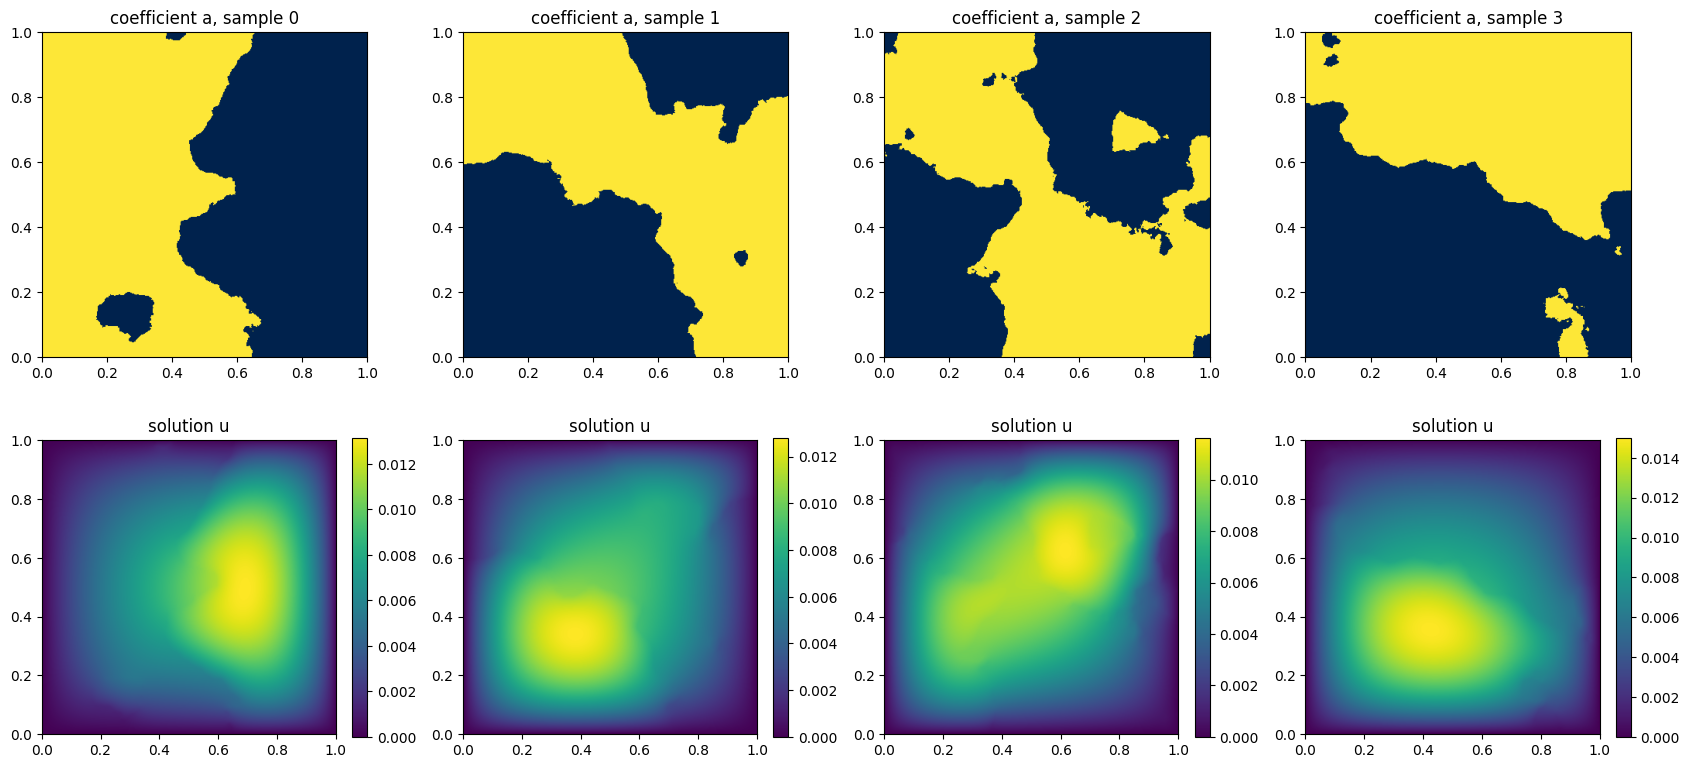

In [6]:
fig, axs = plt.subplots(2, 4, figsize=(17, 8))
for j in range(4):
    im = axs[0, j].imshow(a_test[j].T, origin="lower", extent=[0, 1, 0, 1], cmap="cividis")
    axs[0, j].set_title(f"coefficient a, sample {j}")
    im2 = axs[1, j].imshow(u_test[j].T, origin="lower", extent=[0, 1, 0, 1], cmap="viridis")
    axs[1, j].set_title("solution u"); fig.colorbar(im2, ax=axs[1, j], fraction=0.046)
plt.tight_layout(); plt.show()

## 4. The 2-d Fourier Neural Operator
Input channels $(a(x), x_1, x_2)$, lifted to $d_v = 32$ channels; 4 Fourier layers
$v\mapsto\sigma(Wv+\mathcal F^{-1}(R\cdot\mathcal Fv))$ keeping the modes $|k_1|\le 12$, $0\le k_2\le 12$
(the two "corners" of the real FFT); then the pointwise projection $Q$.

Because the Dirichlet problem is **not periodic**, the hidden state is zero-padded on two sides before the
Fourier layers and cropped afterwards (as in the authors' code). We pad by a fixed *fraction* of the
domain, so that the padding means the same thing at every resolution. Inputs and outputs are normalised
by scalar means and standard deviations, which are also resolution-independent.

In [7]:
class SpectralConv2d(nn.Module):
    def __init__(self, c_in, c_out, m1, m2):
        super().__init__()
        self.m1, self.m2 = m1, m2
        scale = 1 / (c_in * c_out)
        self.w1 = nn.Parameter(scale * torch.rand(c_in, c_out, m1, m2, dtype=torch.cfloat))   # k1 >= 0 corner
        self.w2 = nn.Parameter(scale * torch.rand(c_in, c_out, m1, m2, dtype=torch.cfloat))   # k1 <  0 corner

    def forward(self, v):                                  # v: (B, C, n1, n2)
        B, C, n1, n2 = v.shape
        vh = torch.fft.rfft2(v)                            # (B, C, n1, n2//2+1)
        out = torch.zeros(B, self.w1.shape[1], n1, n2 // 2 + 1, dtype=torch.cfloat, device=v.device)
        m1, m2 = min(self.m1, n1 // 2), min(self.m2, n2 // 2 + 1)
        out[:, :, :m1, :m2] = torch.einsum("bixy,ioxy->boxy", vh[:, :, :m1, :m2], self.w1[:, :, :m1, :m2])
        out[:, :, -m1:, :m2] = torch.einsum("bixy,ioxy->boxy", vh[:, :, -m1:, :m2], self.w2[:, :, :m1, :m2])
        return torch.fft.irfft2(out, s=(n1, n2))


class FNO2d(nn.Module):
    def __init__(self, modes=MODES, width=WIDTH, layers=LAYERS, pad_frac=PAD_FRAC):
        super().__init__()
        self.pad_frac = pad_frac
        self.P = nn.Linear(3, width)                                        # (a, x1, x2) -> width
        self.spectral = nn.ModuleList([SpectralConv2d(width, width, modes, modes) for _ in range(layers)])
        self.W = nn.ModuleList([nn.Conv2d(width, width, 1) for _ in range(layers)])
        self.Q = nn.Sequential(nn.Linear(width, 128), nn.GELU(), nn.Linear(128, 1))

    def forward(self, a):                                  # a: (B, s, s), normalised; grid includes the boundary
        B, s, _ = a.shape
        x = torch.linspace(0, 1, s, device=a.device, dtype=a.dtype)
        X1, X2 = torch.meshgrid(x, x, indexing="ij")
        v = self.P(torch.stack([a, X1.expand(B, s, s), X2.expand(B, s, s)], dim=-1)).permute(0, 3, 1, 2)
        pad = int(round(self.pad_frac * s))
        v = F.pad(v, (0, pad, 0, pad))
        for l, (K, W) in enumerate(zip(self.spectral, self.W)):
            v = K(v) + W(v)
            if l < len(self.spectral) - 1: v = F.gelu(v)
        v = v[:, :, :s, :s]
        return self.Q(v.permute(0, 2, 3, 1)).squeeze(-1)  # (B, s, s)


def rel_l2(pred, true):
    return (pred - true).flatten(1).norm(dim=1) / true.flatten(1).norm(dim=1)

# scalar normalisation (resolution independent)
a_mean, a_std = a_train.mean().item(), a_train.std().item()
u_mean, u_std = u_train.mean().item(), u_train.std().item()
enc_a = lambda a: (a - a_mean) / a_std
dec_u = lambda v: v * u_std + u_mean

model = FNO2d().to(device)
n_par = sum(p.numel() * (2 if p.is_complex() else 1) for p in model.parameters())
print(f"FNO2d parameters: {n_par:,} (real numbers; complex weights counted twice)")

FNO2d parameters: 2,368,001 (real numbers; complex weights counted twice)


## 5. Training at resolution `S_TRAIN`

In [8]:
stride = (S_SOLVE - 1) // (S_TRAIN - 1)
Xtr, Ytr = enc_a(a_train[:, ::stride, ::stride]).to(device), u_train[:, ::stride, ::stride].to(device)
Xte, Yte = enc_a(a_test[:, ::stride, ::stride]).to(device),  u_test[:, ::stride, ::stride].to(device)
print("training grid:", tuple(Xtr.shape[1:]))

def predict(model, X, batch=20):
    model.eval()
    with torch.no_grad():
        return torch.cat([dec_u(model(X[i:i + batch])) for i in range(0, len(X), batch)])

def evaluate(model, X, Y, batch=20):
    return rel_l2(predict(model, X, batch), Y).cpu()

opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DEC)
sched = torch.optim.lr_scheduler.StepLR(opt, step_size=STEP, gamma=GAMMA)
hist = {"train": [], "test": []}
t0 = time.time()
for ep in range(EPOCHS):
    model.train()
    perm = torch.randperm(N_TRAIN, device=device)
    tot = 0.0
    for i in range(0, N_TRAIN, BATCH):
        idx = perm[i:i + BATCH]
        loss = rel_l2(dec_u(model(Xtr[idx])), Ytr[idx]).mean()
        opt.zero_grad(); loss.backward(); opt.step()
        tot += loss.item() * len(idx)
    sched.step()
    hist["train"].append(tot / N_TRAIN)
    hist["test"].append(evaluate(model, Xte, Yte).mean().item())
    if ep % max(1, EPOCHS // 20) == 0 or ep == EPOCHS - 1:
        print(f"epoch {ep:4d} | train {hist['train'][-1]:.4f} | test {hist['test'][-1]:.4f} | "
              f"lr {sched.get_last_lr()[0]:.1e} | {time.time() - t0:.0f} s")
torch.save(model.state_dict(), f"fno_darcy_s{S_TRAIN}.pt")
print(f"final test relative L2 error at s={S_TRAIN}: {hist['test'][-1]:.4f}   (paper, FNO at s=85: 0.0108)")

training grid: (85, 85)
epoch    0 | train 0.3200 | test 0.1275 | lr 1.0e-03 | 6 s
epoch   25 | train 0.0216 | test 0.0229 | lr 1.0e-03 | 73 s
epoch   50 | train 0.0175 | test 0.0188 | lr 1.0e-03 | 139 s
epoch   75 | train 0.0169 | test 0.0192 | lr 1.0e-03 | 205 s
epoch  100 | train 0.0129 | test 0.0146 | lr 5.0e-04 | 270 s
epoch  125 | train 0.0122 | test 0.0142 | lr 5.0e-04 | 336 s
epoch  150 | train 0.0123 | test 0.0145 | lr 5.0e-04 | 402 s
epoch  175 | train 0.0114 | test 0.0182 | lr 5.0e-04 | 468 s
epoch  200 | train 0.0099 | test 0.0119 | lr 2.5e-04 | 534 s
epoch  225 | train 0.0093 | test 0.0123 | lr 2.5e-04 | 600 s
epoch  250 | train 0.0091 | test 0.0119 | lr 2.5e-04 | 666 s
epoch  275 | train 0.0093 | test 0.0126 | lr 2.5e-04 | 731 s
epoch  300 | train 0.0084 | test 0.0109 | lr 1.3e-04 | 797 s
epoch  325 | train 0.0082 | test 0.0111 | lr 1.3e-04 | 863 s
epoch  350 | train 0.0080 | test 0.0105 | lr 1.3e-04 | 929 s
epoch  375 | train 0.0077 | test 0.0105 | lr 1.3e-04 | 995 s
epo

## 6. Results
### 6a. Learning curves

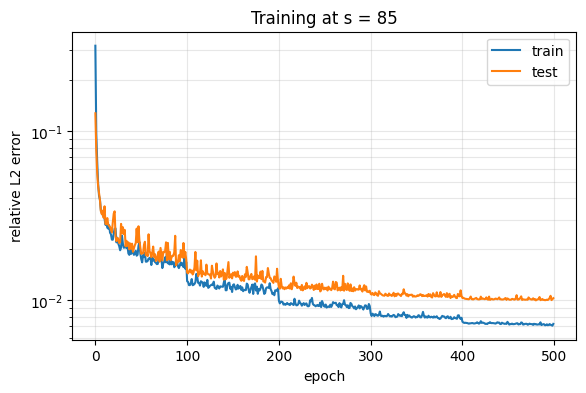

In [9]:
plt.figure(figsize=(6.5, 4))
plt.semilogy(hist["train"], label="train"); plt.semilogy(hist["test"], label="test")
plt.xlabel("epoch"); plt.ylabel("relative L2 error"); plt.title(f"Training at s = {S_TRAIN}")
plt.grid(alpha=.3, which="both"); plt.legend(); plt.show()

### 6b. Predictions on unseen test samples (best, median, worst)

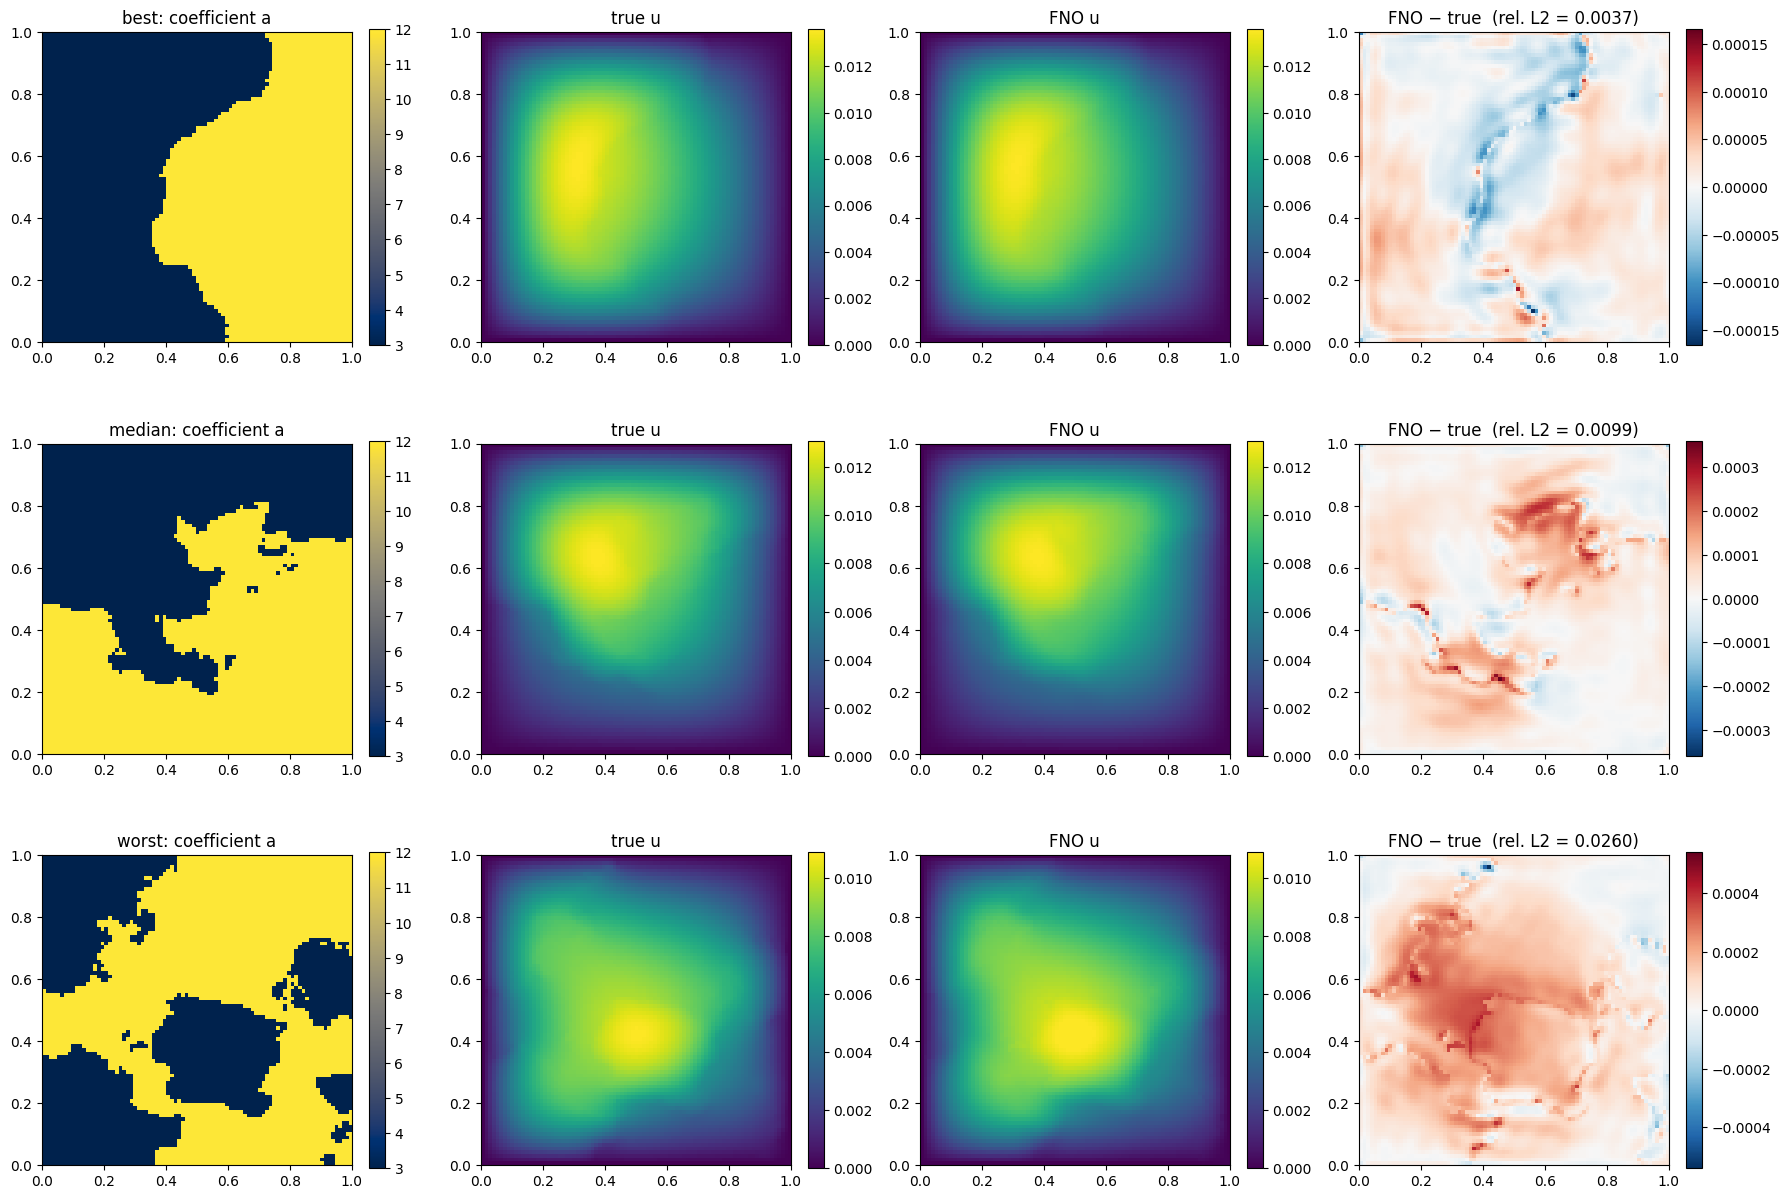

In [10]:
errs_test = evaluate(model, Xte, Yte)
order = torch.argsort(errs_test)
picks = [order[0].item(), order[len(order) // 2].item(), order[-1].item()]
P_te = predict(model, Xte).cpu()
fig, axs = plt.subplots(3, 4, figsize=(18, 12.5))
for r, (i, lab) in enumerate(zip(picks, ["best", "median", "worst"])):
    a_i = a_test[i, ::stride, ::stride]; u_i = Yte[i].cpu(); p_i = P_te[i]; e_i = p_i - u_i
    vmin, vmax = u_i.min().item(), u_i.max().item(); emax = e_i.abs().max().item()
    panels = [(a_i, "coefficient a", "cividis", None, None), (u_i, "true u", "viridis", vmin, vmax),
              (p_i, "FNO u", "viridis", vmin, vmax), (e_i, f"FNO − true  (rel. L2 = {errs_test[i]:.4f})", "RdBu_r", -emax, emax)]
    for c, (img, t, cm, lo, hi) in enumerate(panels):
        im = axs[r, c].imshow(img.T, origin="lower", extent=[0, 1, 0, 1], cmap=cm, vmin=lo, vmax=hi)
        axs[r, c].set_title(f"{lab}: {t}" if c == 0 else t); fig.colorbar(im, ax=axs[r, c], fraction=0.046)
plt.tight_layout(); plt.show()

### 6c. Error distribution, and where the errors are
Left: histogram of per-sample relative errors. Right: the absolute error averaged over the test set,
normalised by the mean of $|u|$. Errors concentrate where the solution is hardest to represent:
across the interfaces of $a$, where $\nabla u$ jumps, and near the boundary. Note that the FNO does not
enforce $u=0$ on $\partial D$ exactly; it only learns it approximately from the data.

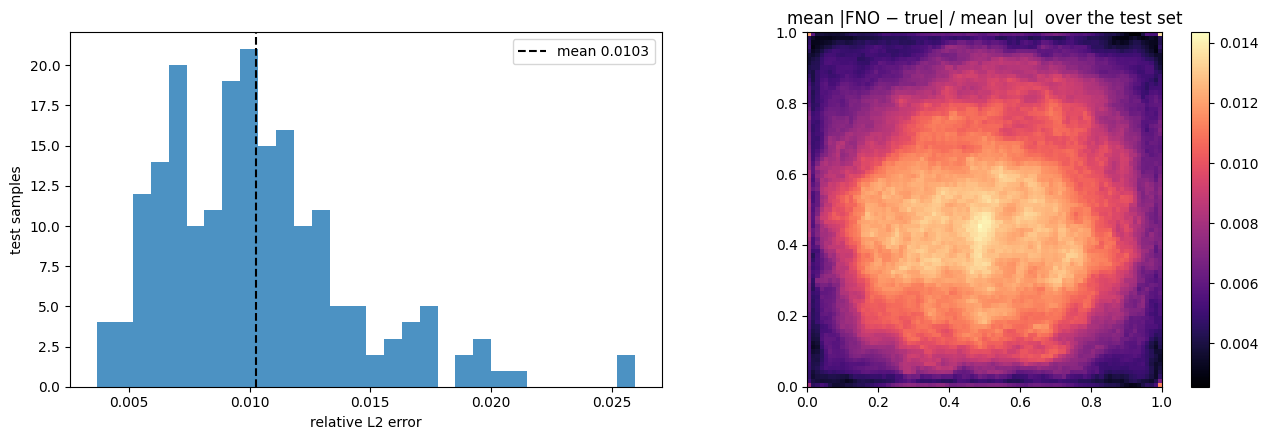

In [11]:
mean_abs_err = (P_te - Yte.cpu()).abs().mean(0) / Yte.cpu().abs().mean()
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
axs[0].hist(errs_test.numpy(), bins=30, alpha=.8)
axs[0].axvline(errs_test.mean(), color="k", ls="--", label=f"mean {errs_test.mean():.4f}")
axs[0].set_xlabel("relative L2 error"); axs[0].set_ylabel("test samples"); axs[0].legend()
im = axs[1].imshow(mean_abs_err.T, origin="lower", extent=[0, 1, 0, 1], cmap="magma")
axs[1].set_title("mean |FNO − true| / mean |u|  over the test set"); fig.colorbar(im, ax=axs[1])
plt.tight_layout(); plt.show()

### 6d. Zero-shot evaluation at other resolutions
The **same** trained model, evaluated on the test set subsampled at resolutions it never saw.
(The paper's Table 4 instead trains a separate model per resolution; see 6e.)

Expect this to be less clean than for Burgers. The input $a$ is discontinuous, so its subsamples at
different resolutions are genuinely different-looking inputs: a coarse grid represents each interface as
a coarse staircase, a fine grid as a fine one. The model has only seen the training resolution's version.
A modest increase in error away from `S_TRAIN` is therefore expected; how much depends on how well the
model is trained. (In a short test run trained at 36×36, the error roughly doubled at 141×141.)

s =   36: mean relative L2 = 0.1036
s =   71: mean relative L2 = 0.0259
s =   85: mean relative L2 = 0.0103   <- training resolution
s =  141: mean relative L2 = 0.0210
s =  211: mean relative L2 = 0.0214
s =  421: mean relative L2 = 0.0229


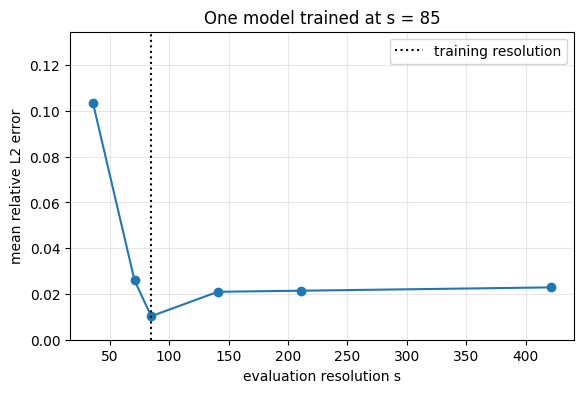

In [12]:
res_list = [s for s in [85, 141, 211, 421, 36, 71] if s <= S_SOLVE and (S_SOLVE - 1) % (s - 1) == 0]
res_list = sorted(set(res_list))
zs = []
for s in res_list:
    st = (S_SOLVE - 1) // (s - 1)
    e = evaluate(model, enc_a(a_test[:, ::st, ::st]).to(device), u_test[:, ::st, ::st].to(device), batch=10).mean().item()
    zs.append(e); print(f"s = {s:4d}: mean relative L2 = {e:.4f}" + ("   <- training resolution" if s == S_TRAIN else ""))
plt.figure(figsize=(6.5, 4))
plt.plot(res_list, zs, "o-"); plt.axvline(S_TRAIN, color="k", ls=":", label="training resolution")
plt.xlabel("evaluation resolution s"); plt.ylabel("mean relative L2 error"); plt.ylim(0, max(zs) * 1.3)
plt.title(f"One model trained at s = {S_TRAIN}"); plt.grid(alpha=.3); plt.legend(); plt.show()

### 6e. (Optional, slow) Table 4 protocol: a separate model at each resolution
Set `RUN_SWEEP = True`. Training at 421×421 is expensive (several hours for 500 epochs on a T4);
reduce `SWEEP_EPOCHS` or drop 421 from `SWEEP_RES` if needed.

In [13]:
RUN_SWEEP = False
SWEEP_RES = [85, 141, 211]
SWEEP_EPOCHS = EPOCHS

if RUN_SWEEP:
    table = {}
    for s in [r for r in SWEEP_RES if (S_SOLVE - 1) % (r - 1) == 0]:
        st = (S_SOLVE - 1) // (s - 1)
        Xs, Ys = enc_a(a_train[:, ::st, ::st]).to(device), u_train[:, ::st, ::st].to(device)
        Xt, Yt = enc_a(a_test[:, ::st, ::st]).to(device),  u_test[:, ::st, ::st].to(device)
        m = FNO2d().to(device)
        o = torch.optim.Adam(m.parameters(), lr=LR, weight_decay=WEIGHT_DEC)
        sc = torch.optim.lr_scheduler.StepLR(o, step_size=STEP, gamma=GAMMA)
        t0 = time.time()
        for ep in range(SWEEP_EPOCHS):
            m.train(); perm = torch.randperm(N_TRAIN, device=device)
            for i in range(0, N_TRAIN, BATCH):
                idx = perm[i:i + BATCH]
                l = rel_l2(dec_u(m(Xs[idx])), Ys[idx]).mean()
                o.zero_grad(); l.backward(); o.step()
            sc.step()
        table[s] = evaluate(m, Xt, Yt, batch=10).mean().item()
        print(f"s = {s:4d}: test error {table[s]:.4f}  ({time.time() - t0:.0f} s)")
    paper = {85: 0.0108, 141: 0.0109, 211: 0.0109, 421: 0.0098}
    plt.figure(figsize=(6.5, 4))
    plt.plot(list(table), list(table.values()), "o-", label="this run")
    plt.plot(list(paper), list(paper.values()), "s--", label="paper, Table 4")
    plt.xlabel("resolution s (train = test)"); plt.ylabel("relative L2 error"); plt.ylim(0, None)
    plt.grid(alpha=.3); plt.legend(); plt.title("Separate model per resolution"); plt.show()